# P(k) vs P(k)+B(k): model-independent Fisher forecast

DESI-Y6-like noiseless mock; legacy MI template ($\ln a$ on 60 nodes over the 80 emulator knots); tree-level B0 from pybird-dev.

## Data

7 skies, 6 redshifts; P0, P2, P4 at $0.01<k<0.2\,h$/Mpc, B0 on triangles with $0.02\le k_i\le0.10\,h$/Mpc; Gaussian covariance, no P–B cross term.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../mi/pk_bk'))
if not os.path.exists('../output/fisher_pb/jacobians_pb.npz'):
    %run ../mi/pk_bk/rebuild.py jacobians     # ~5-10 min, pybird-dev
import fisher
fisher.data_summary()

redshift bins: [0.295, 0.51, 0.706, 0.93, 1.317, 1.491]   (7 skies, sky -> z index [0, 1, 2, 3, 3, 4, 5])
free parameters per data set: 203 (P)   217 (P+B)
   = per-sky EFT (14 P / 16 P+B names x 7 skies) + 80 template amplitudes + 25 growth/geometry
data vector: 399 bins (P0,P2,P4)   1316 bins (+B0: 917 triangles)
delta chi^2 for a 1% move (P+B): h_conv alone 208;  g1 0.27, g2 2e-25, g3 0.38  (0 for an exact symmetry)


## Likelihood

pybird-dev, `eth` basis: one-loop P(k) from the emulator, tree-level B0; per-sky EFT parameters (sky 1 shown).

In [2]:
fisher.likelihood_summary()

P(k)       free: Bb1
           Gaussian prior (sigma): Bb3 5, Bc1 5, Bc2 5, Bc3 5, Bb8 5, Bc4 5, Be1 1, Be2 5, ce2 5, cr4 5, cr6 5, Bb2 5, Bb5 5
P(k)+B(k)  free: Bb1
           Gaussian prior (sigma): Bd1 1, Be1 1, Be5 1, Bb3 5, Bc1 5, Bc2 5, Bc3 5, Bb8 5, Bc4 5, Be2 5, ce2 5, cr4 5, cr6 5, Bb2 5, Bb5 5


## Fisher

Whitened Jacobian on the 60 nodes with the HMC priors ($\sigma_{\ln a}$ 0.5, $\lambda$ 200, $\sigma_{\ln g}$ 0.3, $\sigma_{\ln h}$ 0.05); data response along $g_1$ (ruler) and $g_2$ (amplitude) projected out.

In [3]:
fisher.growth()

sigma(ln P_lin) per knot, marginalized over everything else:
  inside the P(k) window [0.01, 0.2] h/Mpc:  P 0.1131   P+B 0.1022   ratio 0.903   (prior alone 0.1843)
  best single knot for B(k): k = 0.132 h/Mpc, 0.1182 -> 0.0955
  wider priors (s_lna 2, lambda 50): P 0.2735   P+B 0.2306   ratio 0.843
  best knot with the wider priors: k = 0.132 h/Mpc, ratio 0.784


saved /capstor/store/cscs/swissai/a0158/areeves/pybird_model_independent/output/fisher_pb/meeting/fig_bands_pb.png


saved /capstor/store/cscs/swissai/a0158/areeves/pybird_model_independent/output/fisher_pb/meeting/fig_growth_corner.png

fractional sigma(f):   z=0.29  z=0.51  z=0.71  z=0.93  z=1.32  z=1.49
  P(k)         18.6%    18.4%    18.5%    18.6%    19.1%    22.7%
  P(k)+B(k)    12.7%    10.4%     9.7%     9.8%    12.3%    22.1%
  ratio        0.68     0.57     0.52     0.53     0.65     0.97 


saved /capstor/store/cscs/swissai/a0158/areeves/pybird_model_independent/output/fisher_pb/meeting/fig_growth_vs_z.png

GATE: the 60-node basis represents the LCDM template response to 1.7e-02 1.6e-05 1.1e-02 for (omega_cdm, lnAs, h)
GATE: ||J_direct - J_MI M|| / ||J_direct|| = 1.50e-06 (P), 1.38e-06 (P+B)

LCDM recovery, EFT marginalized:
                                           omega_cdm   ln(1e10 As)         h
  P(k)       direct LCDM fit                   0.0023      0.0398      0.0037
  P(k)       through the MI model              0.0023      0.0399      0.0038
  P(k)       through the MI model + its prior      0.0012      0.0156      0.0033
             MI / direct                        0.988       1.002       1.031
  P(k)+B(k)  direct LCDM fit                   0.0016      0.0326      0.0034
  P(k)+B(k)  through the MI model              0.0016      0.0325      0.0034
  P(k)+B(k)  through the MI model + its prior      0.0010      0.0137      0.0031
             MI / direct    

saved /capstor/store/cscs/swissai/a0158/areeves/pybird_model_independent/output/fisher_pb/meeting/fig_cosmo_pb.png


## Linear P(k)

Everything else marginalized; solid: wider priors ($\sigma_{\ln a}$ 2, $\lambda$ 50), dotted: HMC priors; grey bands: P and B data ranges.

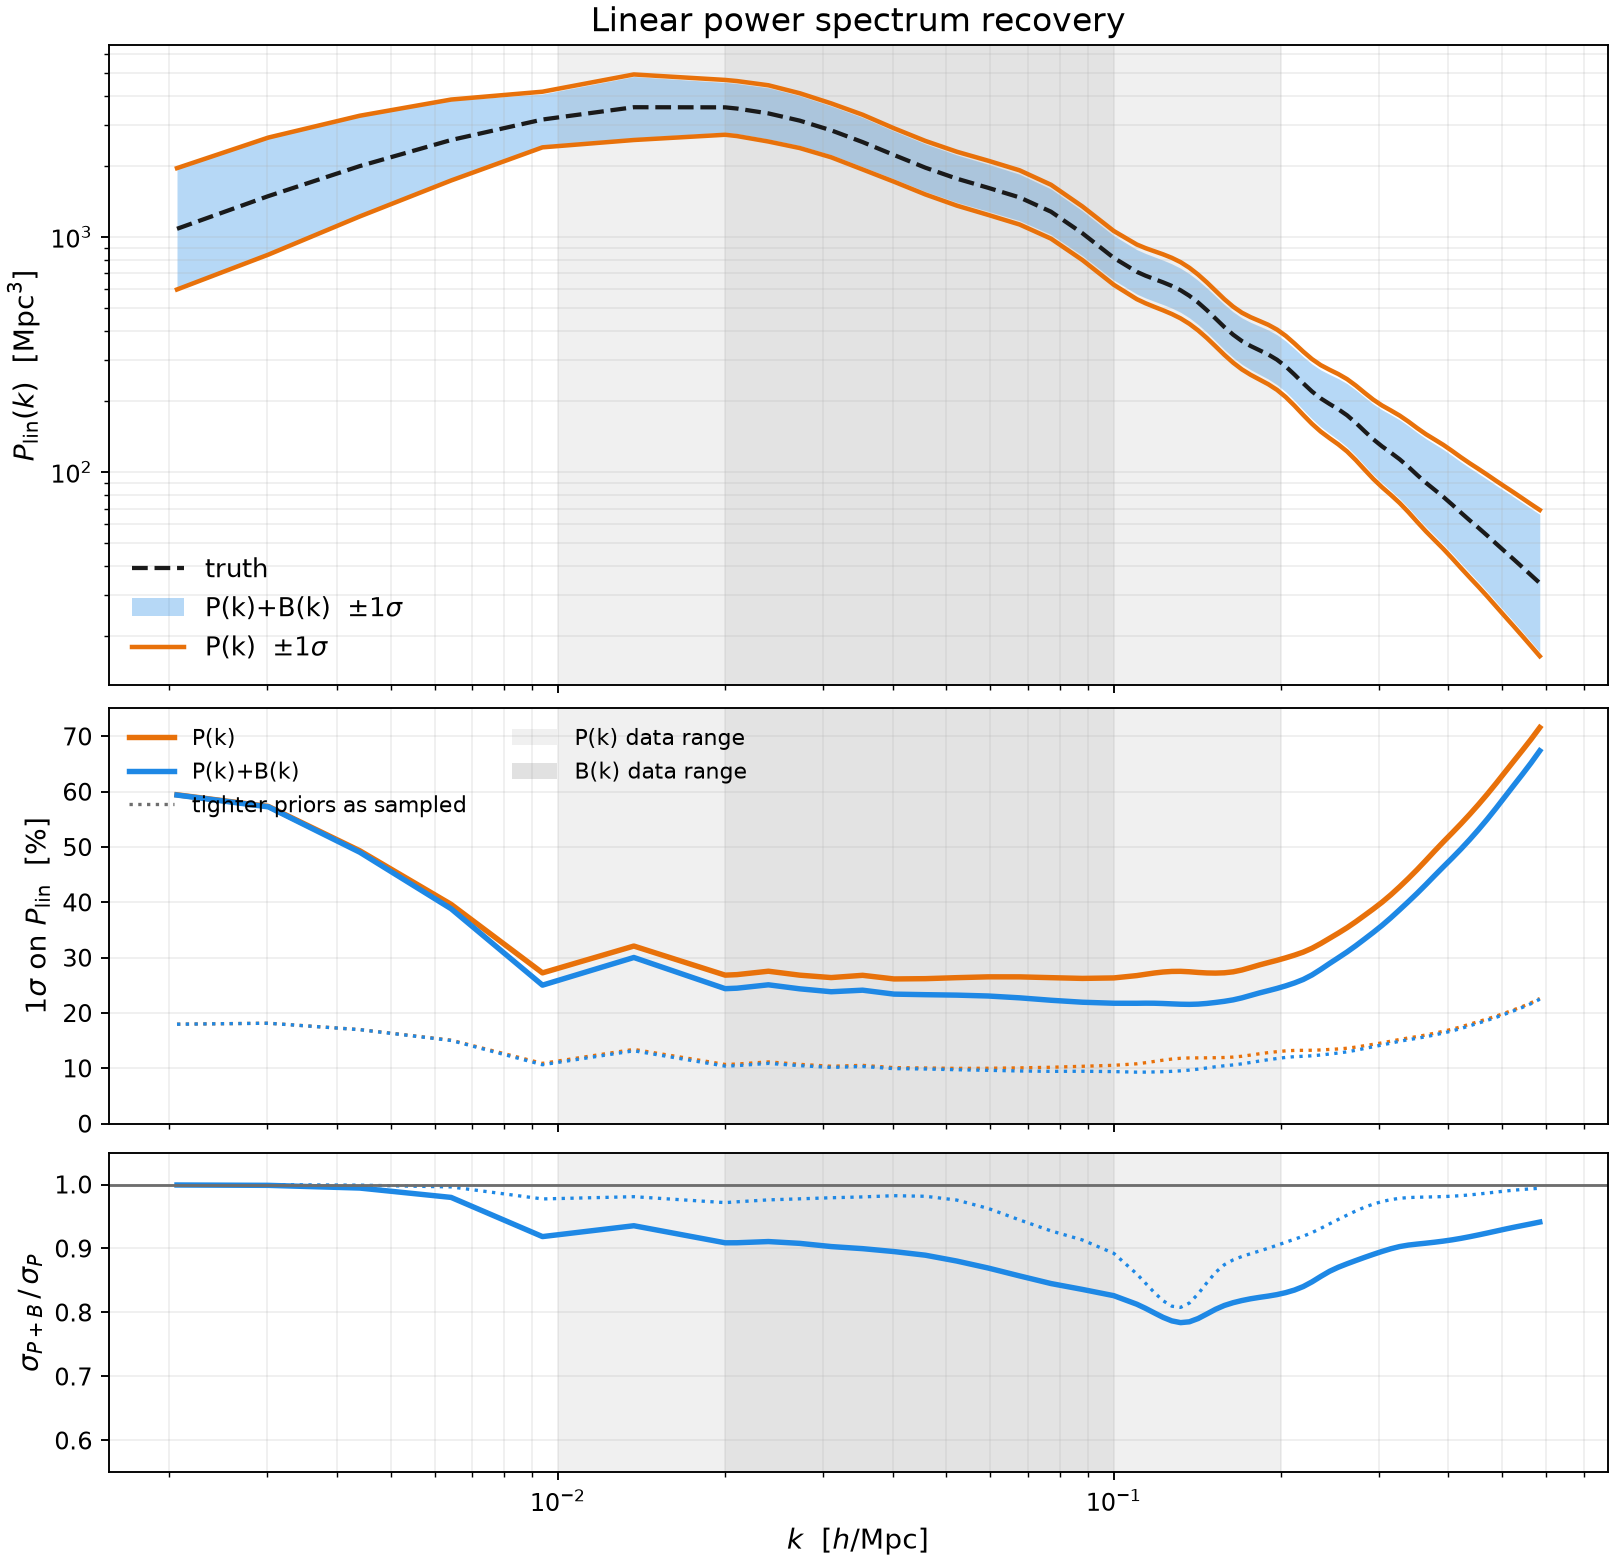

In [4]:
fisher.show('fig_bands_pb.png', 880)

## Growth

$(f, H, D_A)$ at $z=0.71$, and $\sigma(f)$, $\sigma(F_{\rm AP})$ vs $z$.

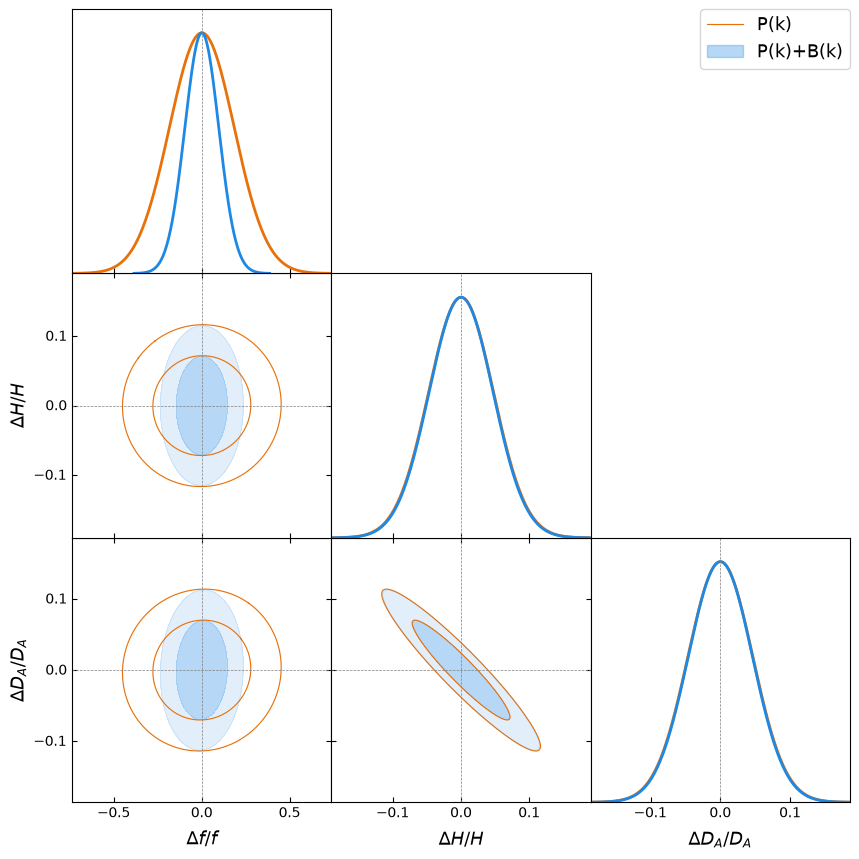

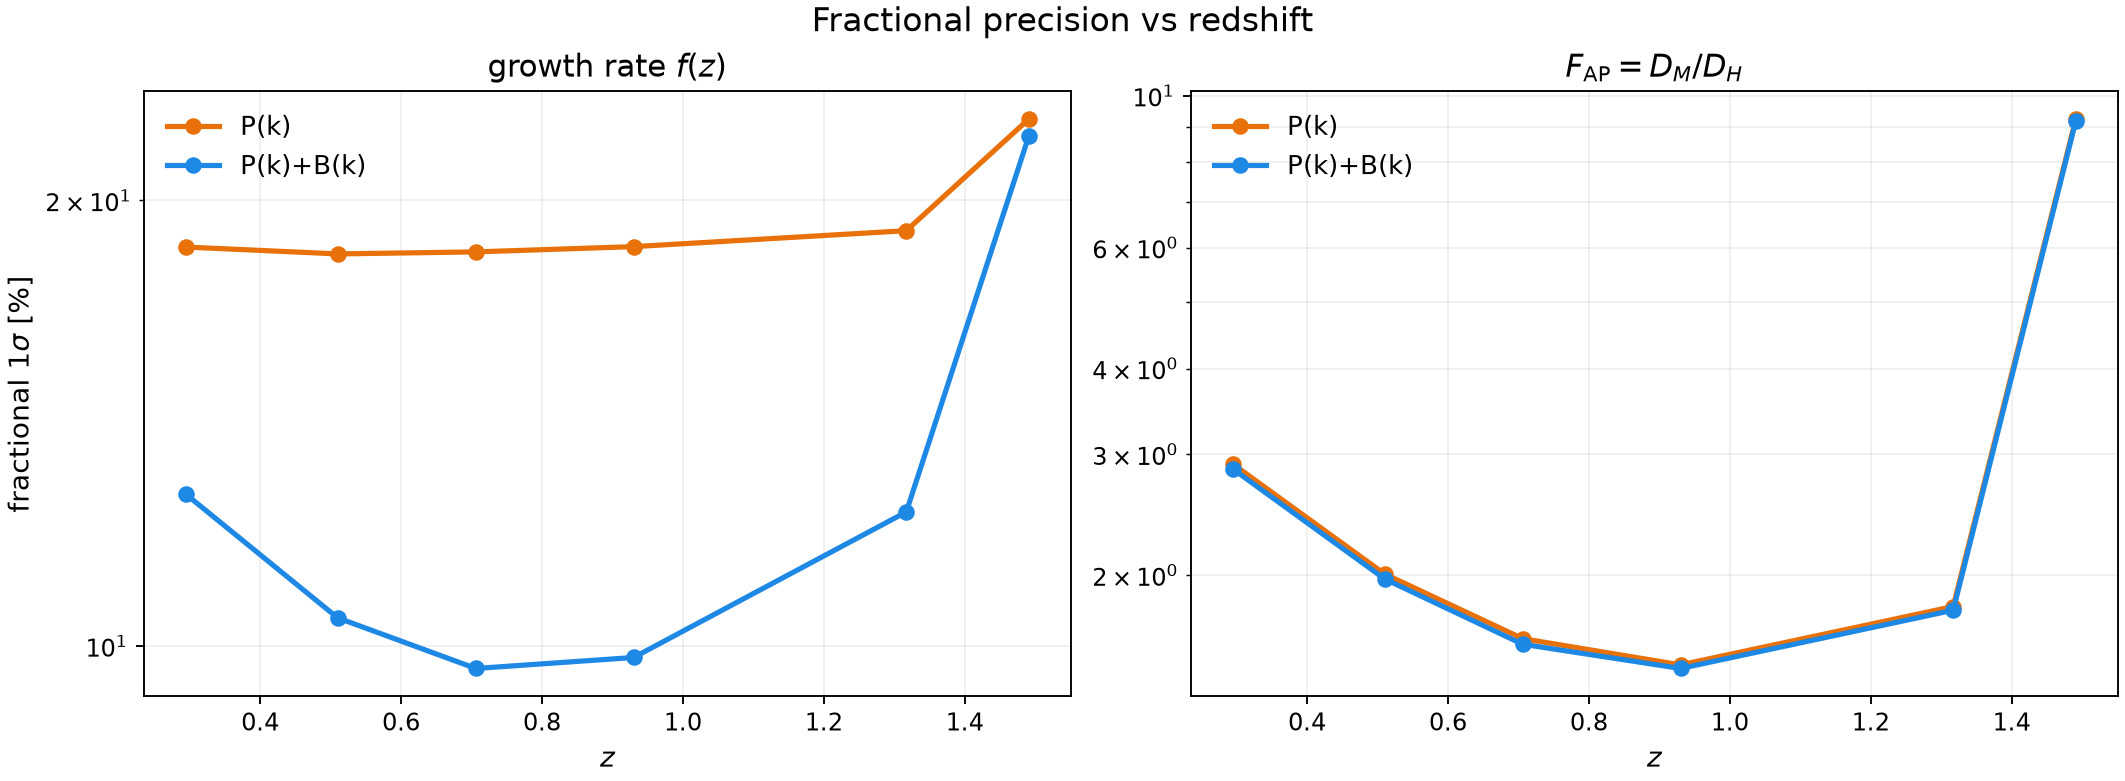

In [5]:
fisher.show('fig_growth_corner.png', 720)
fisher.show('fig_growth_vs_z.png', 980)

## ΛCDM recovery

Dashed: direct ΛCDM fit; solid: the same data through the MI parametrization, MI priors off.

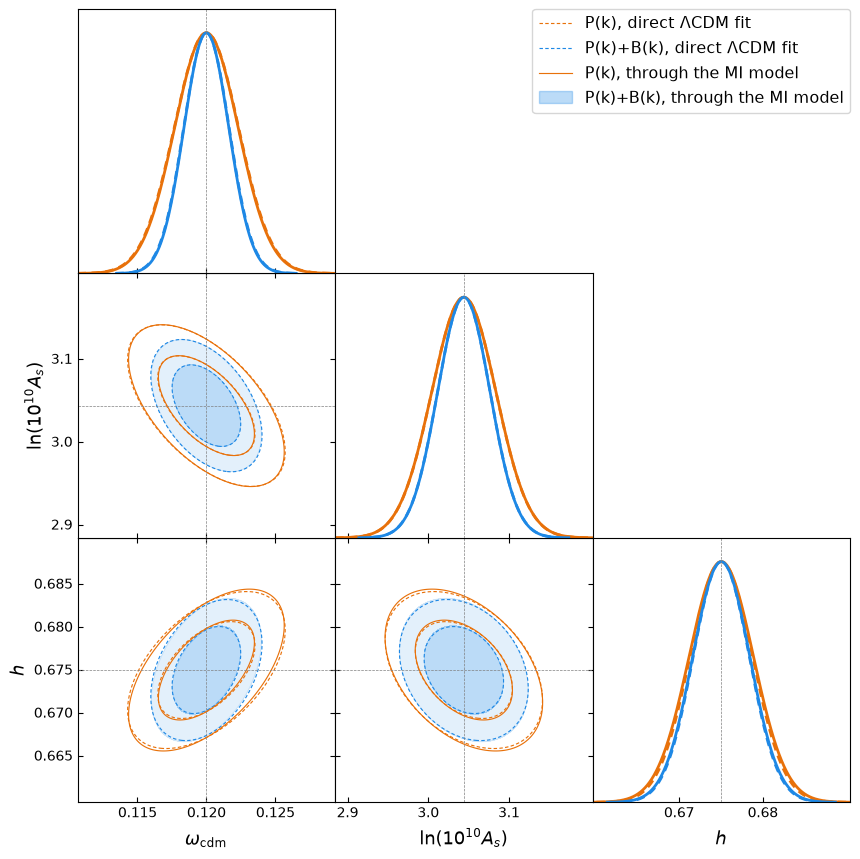

In [6]:
fisher.show('fig_cosmo_pb.png', 760)

## Priors

Each MI prior block on and off, then a scan over $\sigma_{\ln a}$ and $\lambda$.

In [7]:
fisher.prior_audit()

1. THE INDUCED PRIOR ON LCDM, NO DATA AT ALL
                                        omega_cdm  ln(1e10 As)            h
  s_lna                                    0.0091       6.3601     398.4119
  lambda                                   0.0047       0.3414      20.5741
  s_lng                                       inf          inf          inf
  s_lnh                                       inf          inf          inf
  all four together                        0.0035       0.0460       0.0318

  for scale, the DATA alone:
  P(k)                                     0.0023       0.0399       0.0038
  P(k)+B(k)                                0.0016       0.0325       0.0034

2. LCDM WITH EACH BLOCK ON ALONE, AND WITH EACH BLOCK OFF ALONE   [P(k)+B(k)]
                                        omega_cdm  ln(1e10 As)            h
  data only (no MI priors)                 0.0016       0.0325       0.0034
  + s_lna alone                            0.0016       0.0297       0.0034
  + lambda

  as sampled: 0.5 / 200                       0.1022       9.7%     1.94%            0.85%


  s_lna off (1e6)                             0.2883      10.1%     1.99%            0.90%


  lambda off (0)                              0.1547      10.1%     4.80%            1.14%


  s_lng off (1e6)                             0.1090      10.8%     1.99%            0.85%


  template priors off                         0.7763      11.8%     6.17%            2.14%

4. SCAN OVER s_lna AND lambda   [P(k)+B(k)]
  s_lna   lam |   LCDM sigma ratio to data-only |   rough |    band   sig(f)  D_M/r_d   +phase
              |     omega_cdm     lnAs        h |         |                      free     0.2%


... (21 outputs left out)

   10.0    50 |       0.67      0.49      0.93 |   0.139 |   0.290    10.2%    3.12%    1.06%


   10.0    20 |       0.72      0.58      0.93 |   0.218 |   0.296    10.3%    3.93%    1.24%


   10.0     5 |       0.83      0.76      0.96 |   0.430 |   0.310    10.4%    4.84%    1.53%
   10.0     0 |       1.00      1.00      0.99 |  24.495 |   0.460    11.0%    5.85%    1.87%

  ratio: sigma(LCDM) with the MI prior / data only;  rough: 1-sigma second difference of
  ln a the prior allows;  band: mean sigma(ln P_lin) over knots in 0.01 < k < 0.2 h/Mpc

5. lambda = 200 VS NODE SPACING (prior alone)
  spacing  nodes   roughness  equivalent lambda at 0.15
     0.15     60       0.066                        200
     0.25     36       0.066                       1543
     0.40     23       0.066                      10114
     0.60     16       0.067                      51200



saved /capstor/store/cscs/swissai/a0158/areeves/pybird_model_independent/output/fisher_pb/meeting/fig_prior_decomposition.png


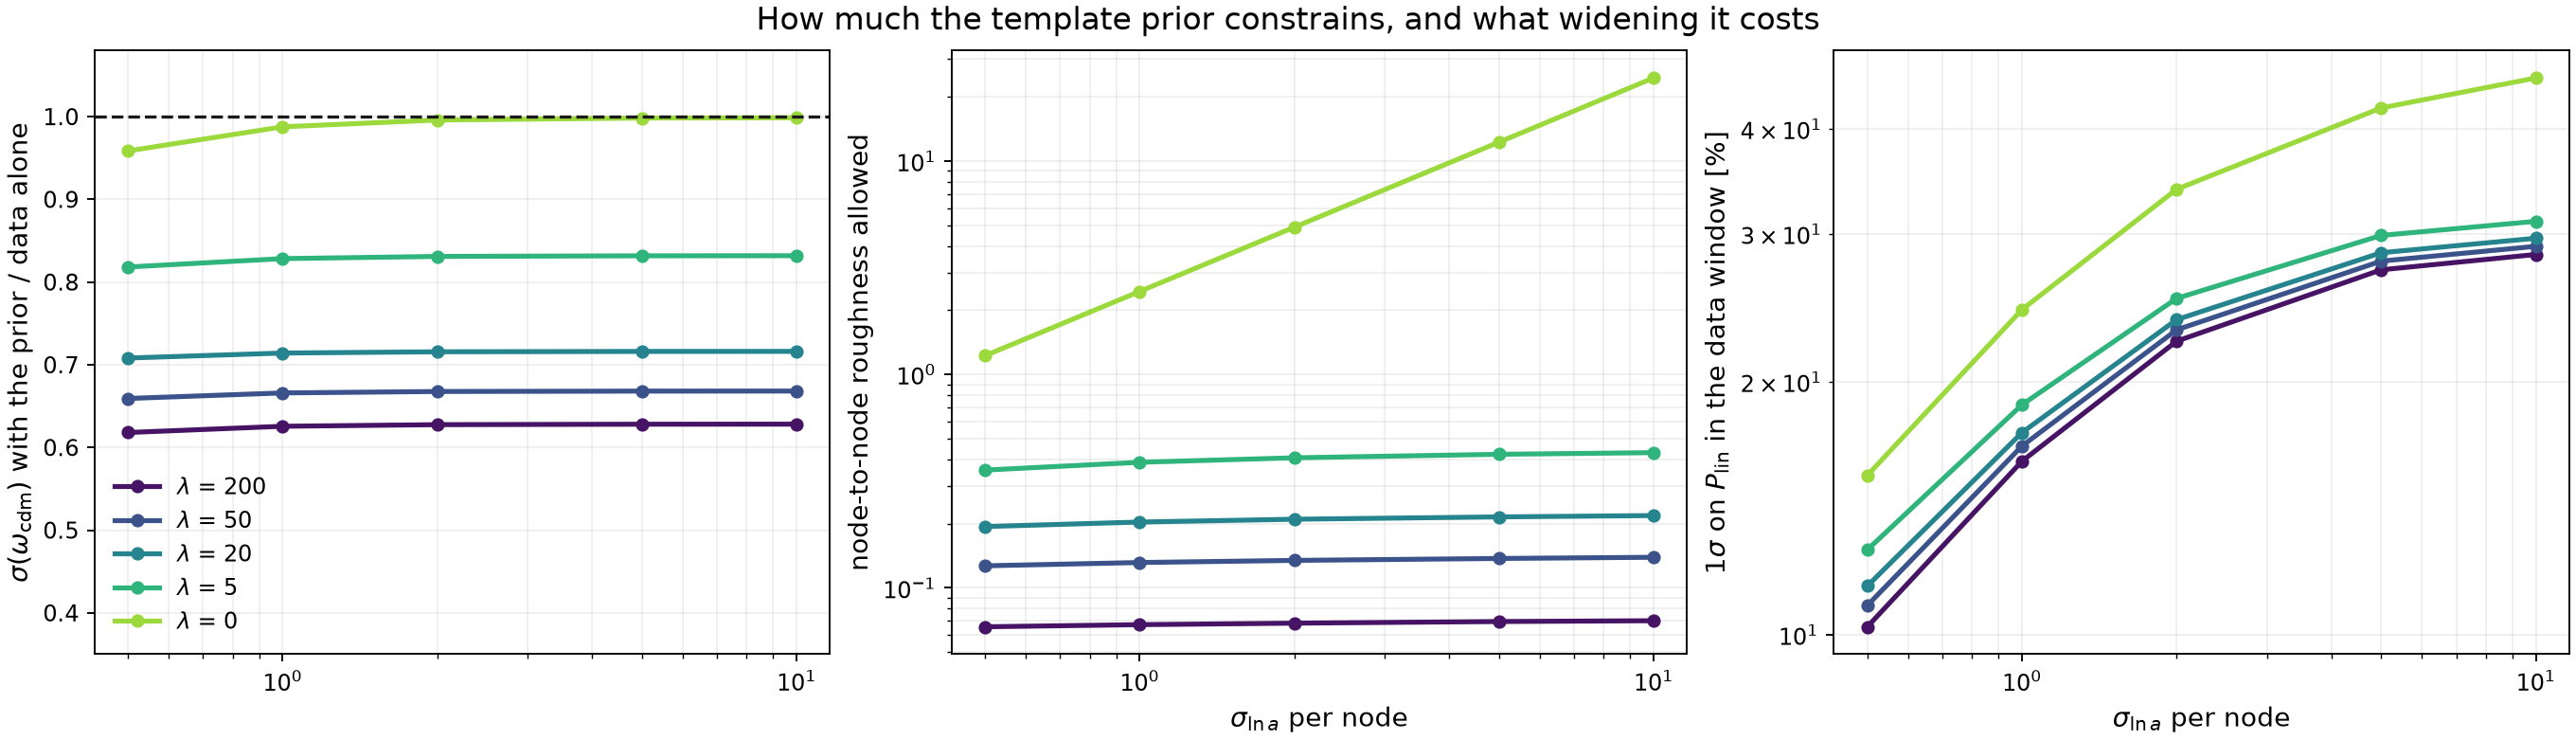

In [8]:
fisher.show('fig_prior_decomposition.png', 1150)

## BAO A: free template

80 free knots, no template prior.

In [9]:
fisher.stage_a()

free 80-knot template, no prior, everything marginalized, z = 0.706
                                          P(k)     P(k)+B(k)
  D_M/r_d                         not measured  not measured
  F_AP = D_M/D_H                         5.05%         3.15%
  isotropic distance / z=0.93            1.28%         1.04%
  f                               not measured        18.95%
  BAO wiggle S/N                           9.4          12.5


## BAO B: smoothness prior

The sampled model (60 nodes, $\lambda=200$); $v=d\ln(1+O)/d\ln k$ is the pattern that slides the wiggles.

In [10]:
fisher.bao()

BAO period in ln k = 2pi/(r_d k): 1.20 at k=0.05, 0.60 at 0.1, 0.30 at 0.2 h/Mpc
slide pattern v = dln(1+O)/dlnk represented by the node basis: 95.7% at spacing 0.15 (60 nodes), 16.4% at spacing 0.60 (16 nodes)
smoothness prior alone allows a template slide of 3.16% (1 sigma) in the 60-node basis



saved /capstor/store/cscs/swissai/a0158/areeves/pybird_model_independent/output/fisher_pb/meeting/fig_phase_prior_explained.png


z = 0.706: fractional 1 sigma vs the phase prior (sigma_delta = how far the template may slide its own wiggles, 6 envelope modes)
 sigma_delta       D_M/r_d  P     P+B       D_H/r_d  P     P+B       F_AP  P      P+B        f  P      P+B
        free       2.13%    1.94%       2.37%    2.17%       1.62%    1.59%      18.46%    9.65%
       5.00%       1.92%    1.76%       2.21%    2.03%       1.61%    1.58%      18.34%    9.50%
       3.00%       1.74%    1.62%       2.06%    1.93%       1.61%    1.58%      18.33%    9.47%
       2.00%       1.54%    1.46%       1.89%    1.80%       1.60%    1.58%      18.32%    9.45%
       1.00%       1.19%    1.16%       1.60%    1.56%       1.60%    1.58%      18.30%    9.39%
       0.50%       0.97%    0.94%       1.43%    1.39%       1.60%    1.57%      18.30%    9.36%
       0.20%       0.88%    0.85%       1.35%    1.32%       1.59%    1.57%      18.30%    9.35%
       0.10%       0.86%    0.83%       1.34%    1.31%       1.59%    1.57%      18.


saved /capstor/store/cscs/swissai/a0158/areeves/pybird_model_independent/output/fisher_pb/meeting/fig_phase_scan.png

Per-redshift fractional 1 sigma:
  no phase prior (the model we sample)
                          z=0.29          z=0.51          z=0.71          z=0.93          z=1.32          z=1.49
    perp  P(k)                2.38%           2.20%           2.13%           2.14%           2.24%           6.12%
    perp  P(k)+B(k)           2.19%           2.02%           1.94%           1.96%           2.05%           6.04%
    par   P(k)                3.12%           2.56%           2.37%           2.29%           2.41%           7.27%
    par   P(k)+B(k)           2.92%           2.36%           2.17%           2.11%           2.27%           7.15%
    F_AP  P(k)                2.90%           2.01%           1.62%           1.48%           1.80%           9.24%
    F_AP  P(k)+B(k)           2.85%           1.98%           1.59%           1.46%           1.78%           9.18%


saved /capstor/store/cscs/swissai/a0158/areeves/pybird_model_independent/output/fisher_pb/meeting/fig_bao_per_z.png


saved /capstor/store/cscs/swissai/a0158/areeves/pybird_model_independent/output/fisher_pb/meeting/fig_bao_corner.png


saved /capstor/store/cscs/swissai/a0158/areeves/pybird_model_independent/output/fisher_pb/meeting/fig_bao_triangle_all_z.png


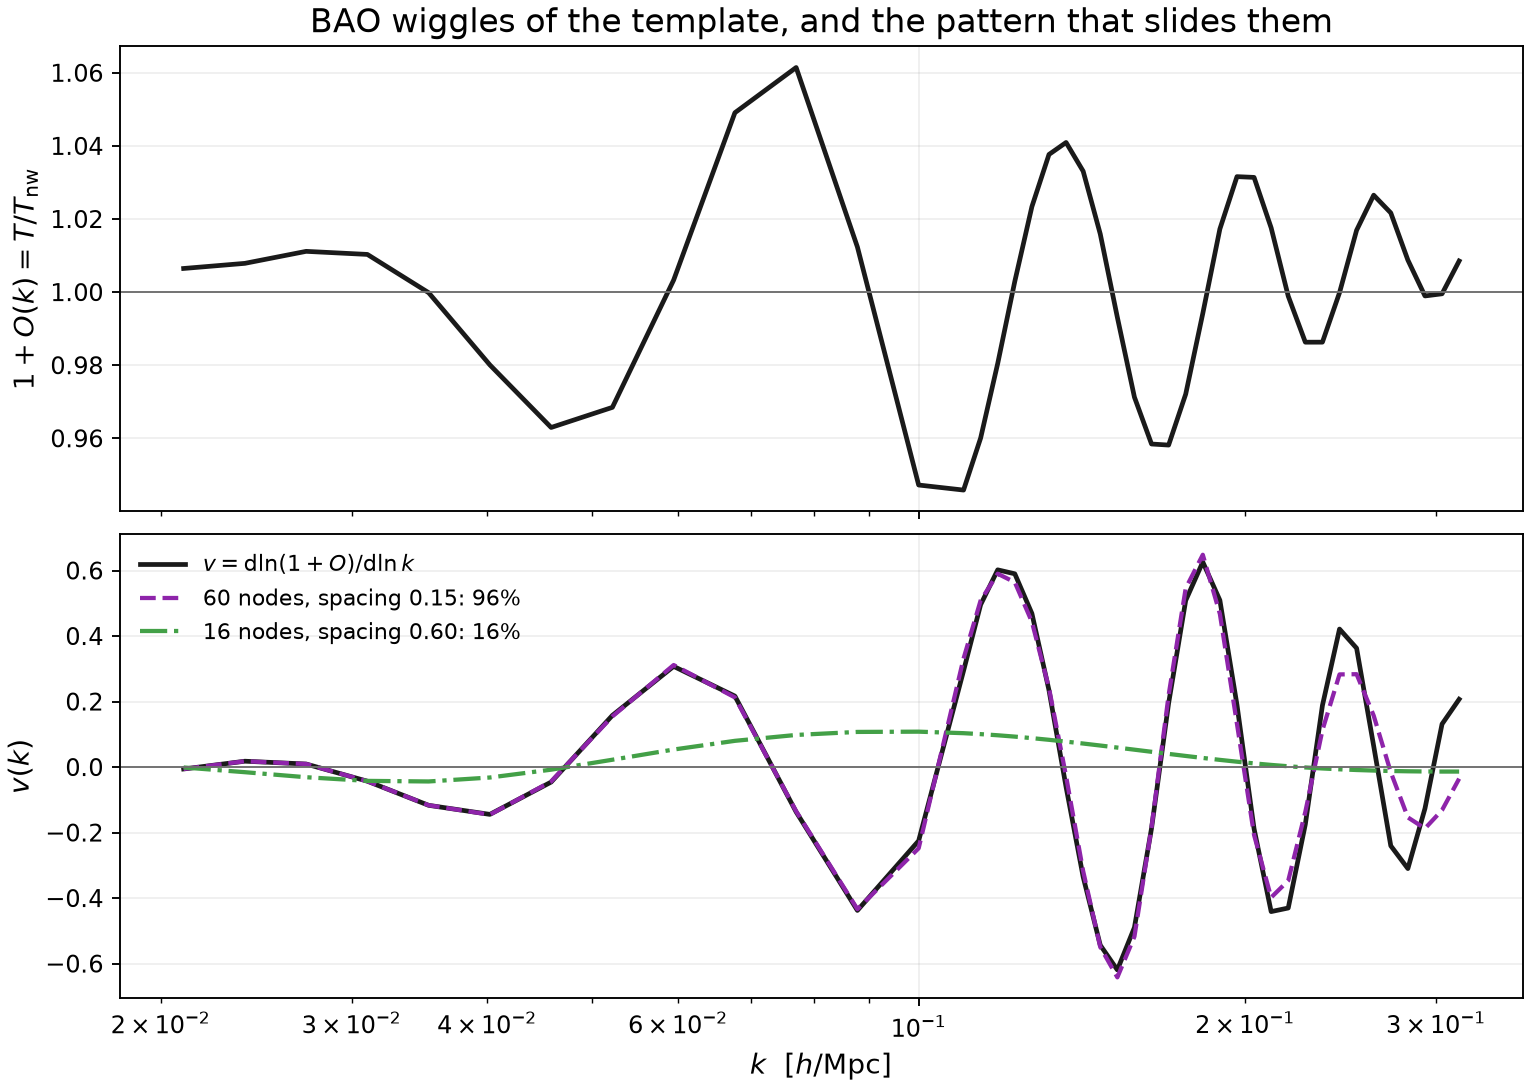

In [11]:
fisher.show('fig_phase_prior_explained.png', 860)

## BAO C: phase prior

Gaussian prior $\sigma_\delta$ on the slide $\delta(k)\,v(k)$, $\delta=\sum_{j=0}^{5}c_j P_j(\ln k)$; broadband and wiggle amplitude free.

In [12]:
import inspect
print(inspect.getsource(fisher.phase_modes))
print(inspect.getsource(fisher.phase_precision))

def phase_modes(Sb, n_phase=N_PHASE):
    """The wiggle-slide patterns, on the ln-a nodes of basis `Sb`: columns v * P_j(ln k).

    A single column (n_phase = 1) pins one GLOBAL slide of the wiggle pattern. That is not
    enough: the template can still drift the phase slowly across k and recover most of the
    freedom (measured: sigma(D_M/r_d) 2.13% -> 1.37% only). The envelopes P_j are Legendre
    polynomials of degree j in ln k rescaled to [-1, 1] over PHASE_RANGE, so column j is a
    slide whose size varies across the band; pinning j = 0..5 leaves the phase fixed
    everywhere and takes sigma(D_M/r_d) to 0.88%, close to the 0.71% of a basis too coarse to
    slide anything. The wiggle AMPLITUDE is never touched -- it is the damping nuisance of a
    BAO fit and stays free."""
    from numpy.polynomial.legendre import legval
    lo, hi = np.log(PHASE_RANGE[0]), np.log(PHASE_RANGE[1])
    x = np.clip((np.log(knots_h) - lo) / (hi - lo) * 2 - 1, -1, 1)
    cols = []
    for j in r

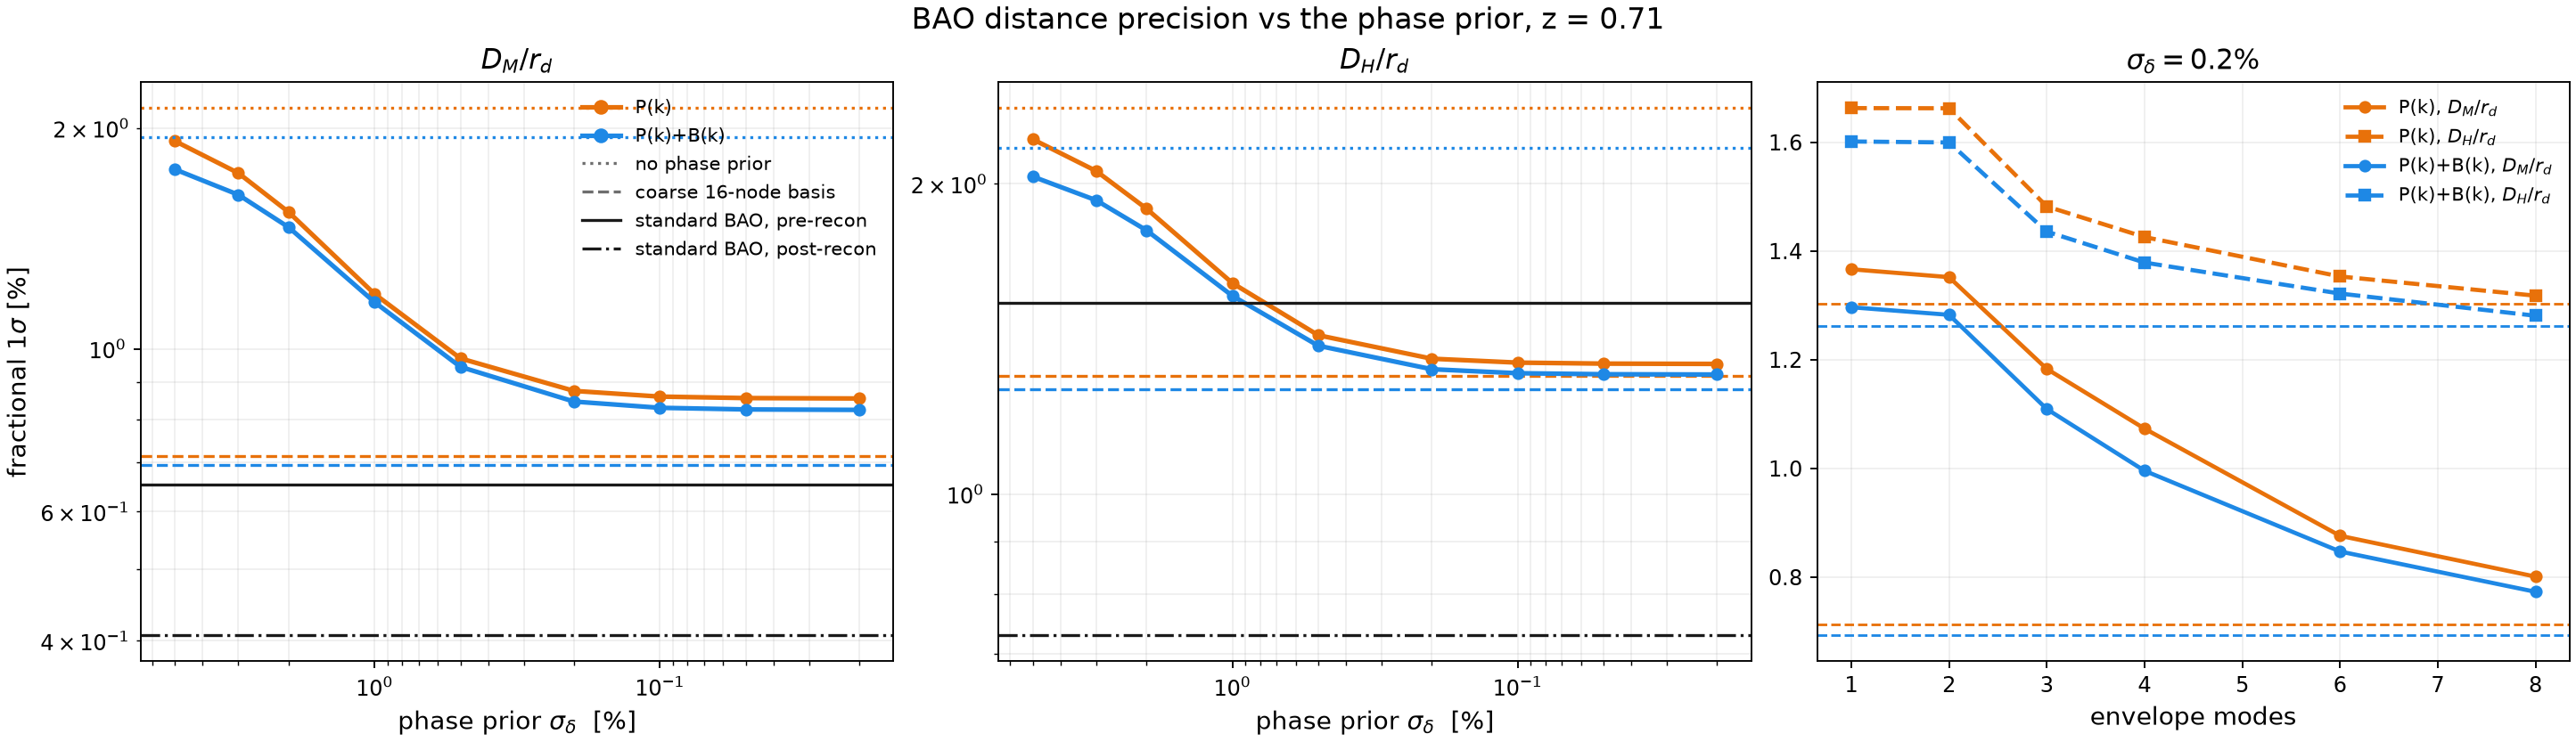

In [13]:
fisher.show('fig_phase_scan.png', 1150)

## P vs P+B per redshift

Solid: no phase prior; dashed: $\sigma_\delta=0.2\%$; grey: standard BAO (Seo & Eisenstein 2007), pre/post-reconstruction.

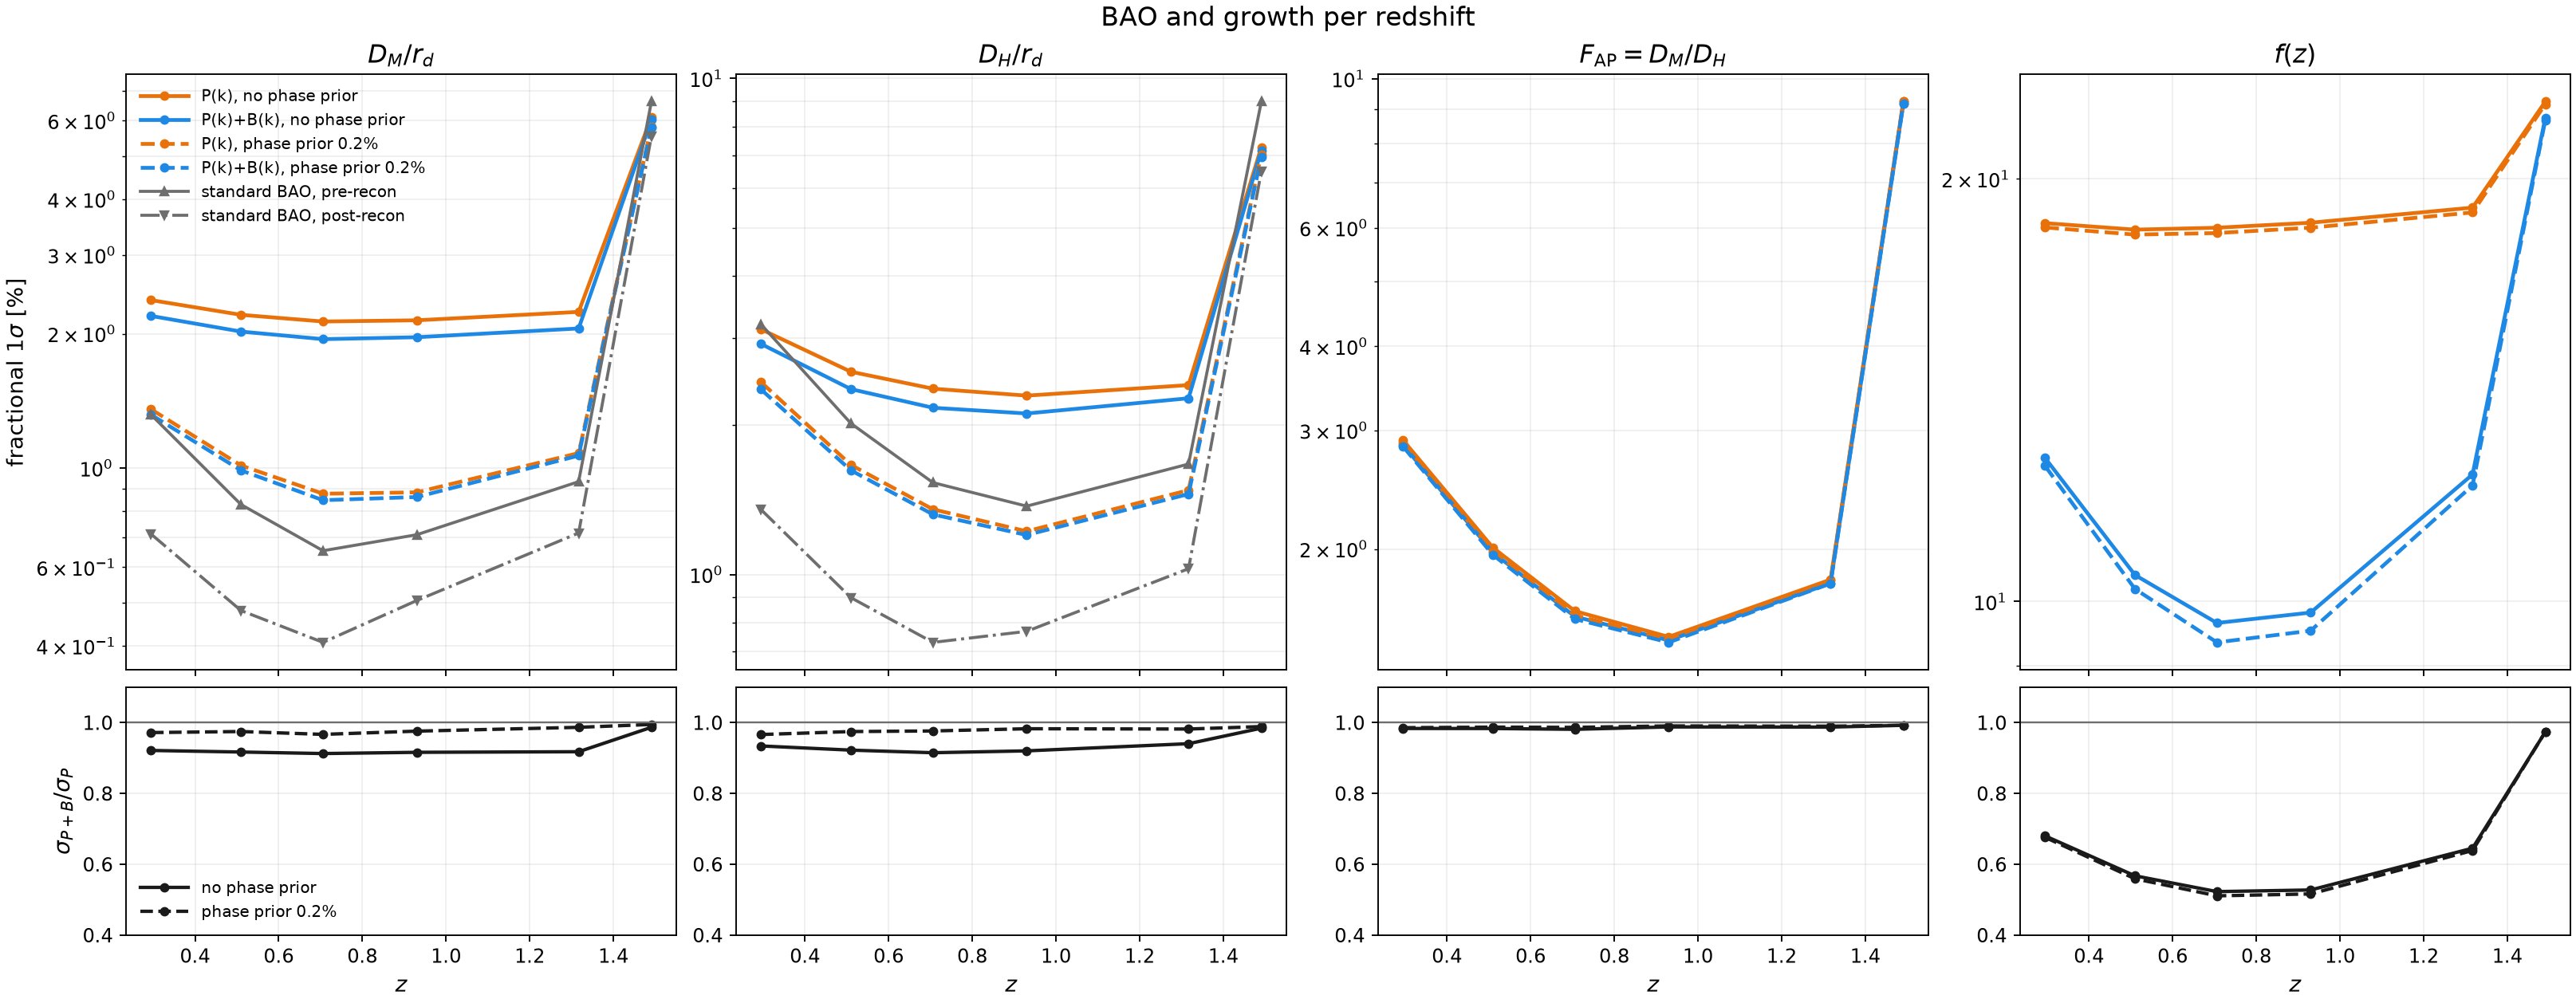

In [14]:
fisher.show('fig_bao_per_z.png', 1150)

## All redshifts

$D_M/r_d$ and $D_H/r_d$ with $\sigma_\delta=0.2\%$, everything else marginalized.

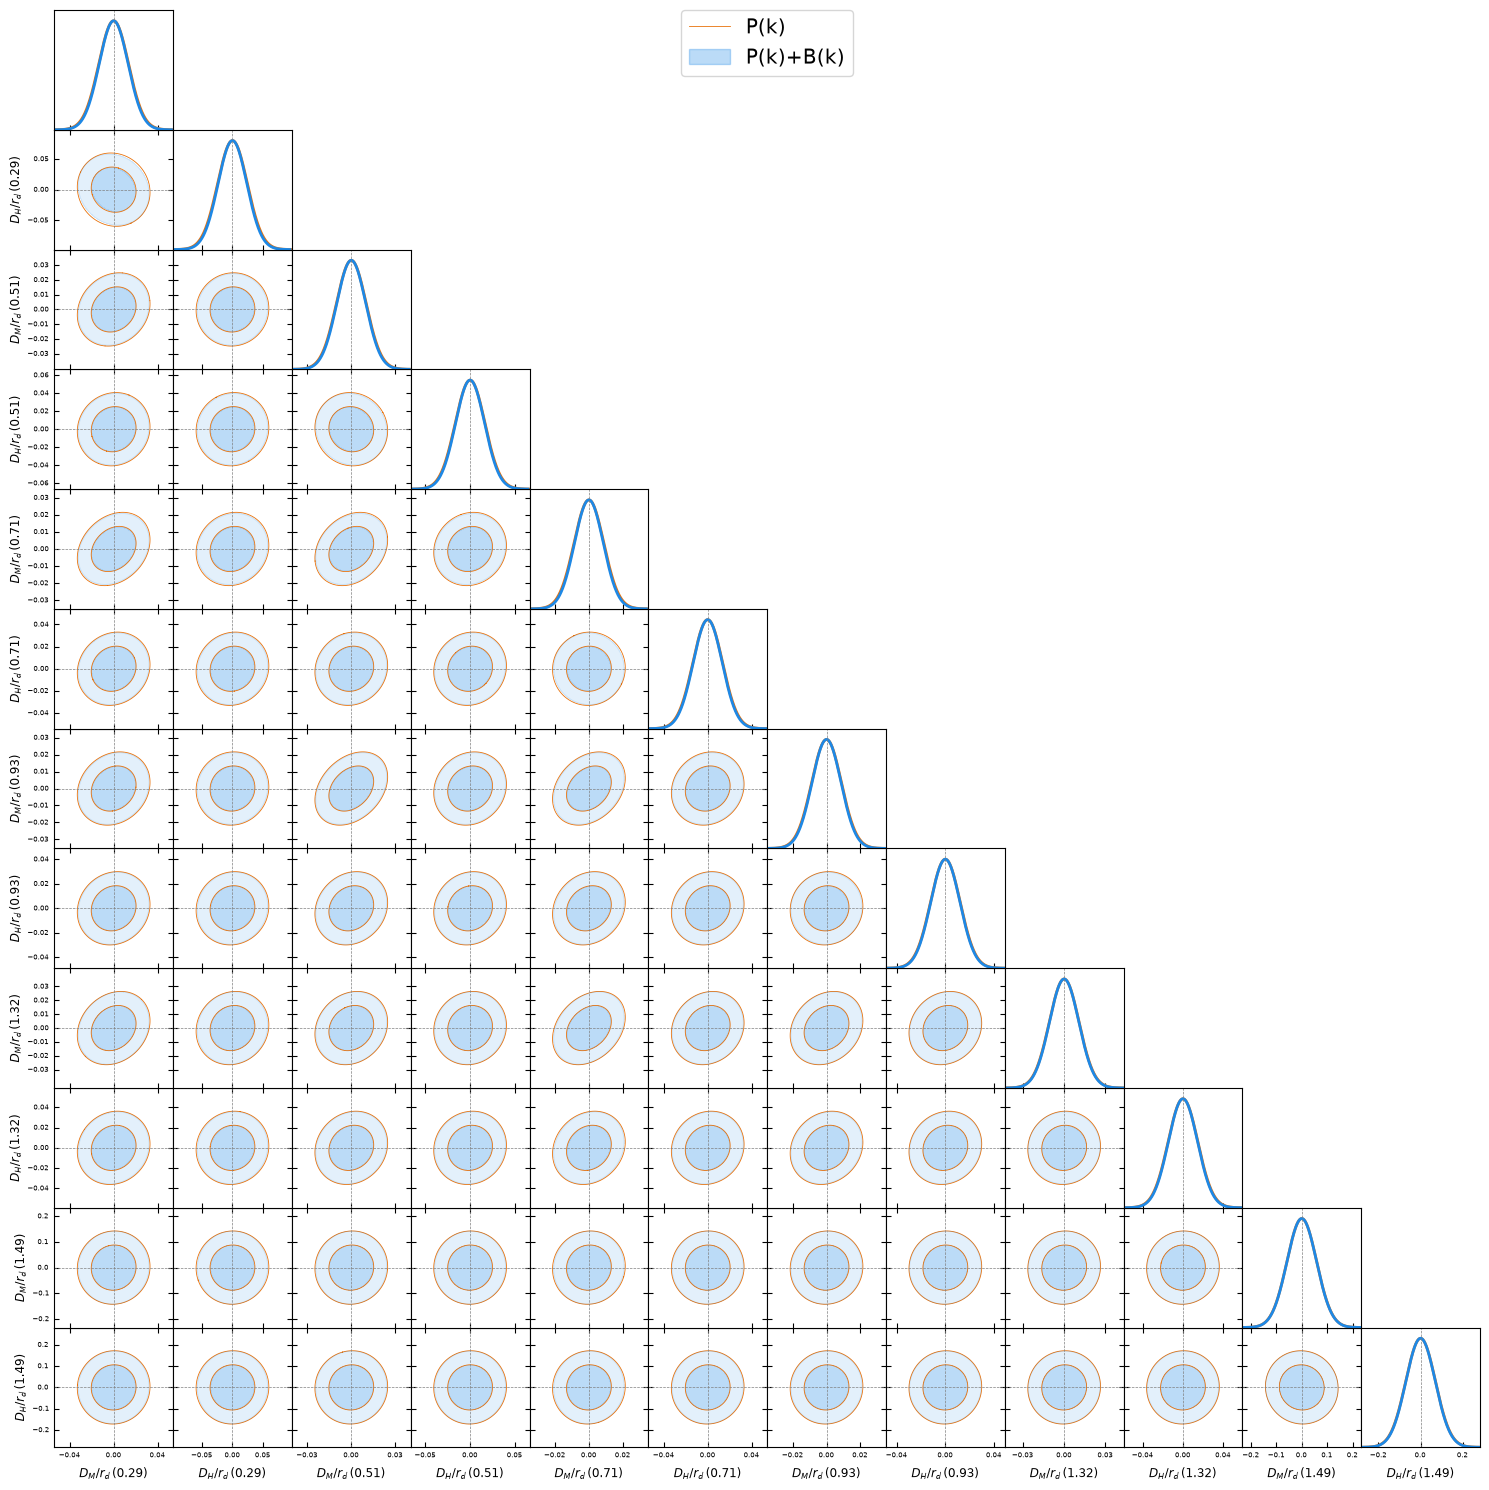

In [15]:
fisher.show('fig_bao_triangle_all_z.png', 1250)

## z = 0.71

Dashed: no phase prior; solid: $\sigma_\delta=0.2\%$.

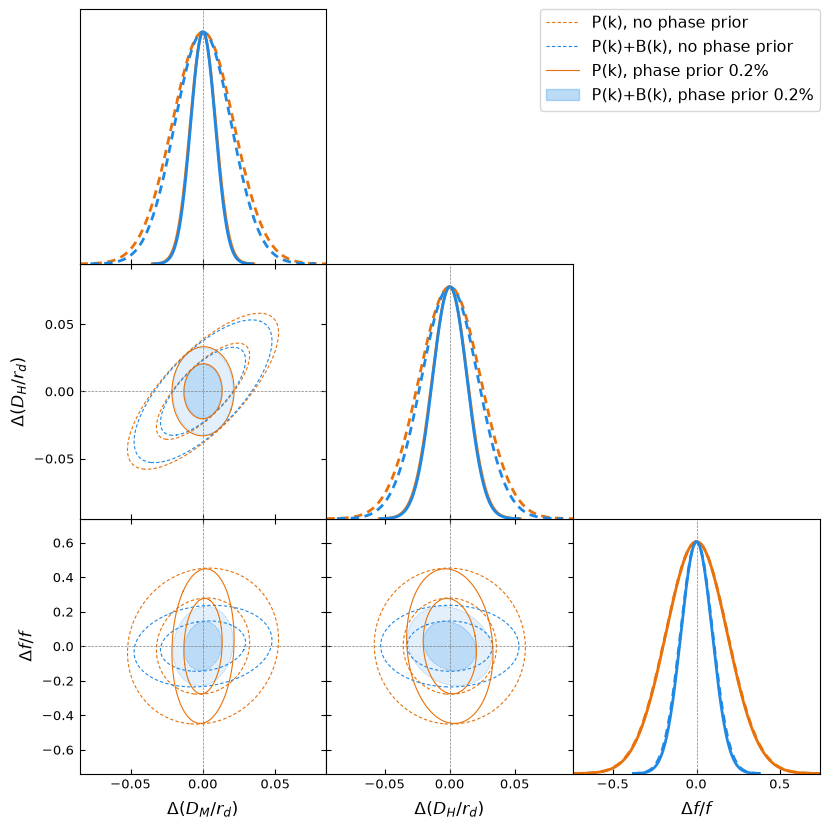

In [16]:
fisher.show('fig_bao_corner.png', 760)